# GRANDE: multiclass classification

GRANDE trains an ensemble of hard, axis-aligned decision trees end-to-end with gradient descent. Every tree
learns its split features, thresholds and leaf values jointly with *instance-wise* leaf weights: for each sample,
the weight of a tree depends on the leaf the sample reaches, and the prediction is the weighted combination of the
reached leaves. Because the trees stay hard and axis-aligned, the model can be inspected like a classic tree ensemble.

This notebook classifies DNA sequences into splice junction types (OpenML dataset 46958, *splice*, curated for
TabArena): exon/intron boundaries (`EI`), intron/exon boundaries (`IE`) or neither (`N`). Every feature is one
nucleotide position of the sequence, a categorical feature. The notebook trains `GRANDEClassifier`, compares it
with XGBoost and CatBoost, and looks inside the ensemble. Hyperparameter tuning works as shown in the binary
classification notebook.

**Requirements:** `pip install "GRANDE[examples] @ git+https://github.com/s-marton/GRANDE.git"` (GRANDE with
matplotlib, OpenML, XGBoost and CatBoost). A GPU is recommended; everything also runs on a CPU, only slower.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import openml
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

from GRANDE import GRANDEClassifier

pd.set_option("display.max_colwidth", None)  # show complete rules
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none, running on the CPU")

GPU: NVIDIA RTX A6000


## 1. Data

GRANDE accepts the class labels as they are (here strings); `classes_` holds them in sorted order and the columns
of `predict_proba` follow that order.

In [2]:
dataset = openml.datasets.get_dataset(46958, download_data=True, download_qualities=False, download_features_meta_data=False)
X, y, categorical_indicator, _ = dataset.get_data(target=dataset.default_target_attribute)
y = y.astype(str)
print(f"{X.shape[0]} samples, {X.shape[1]} features ({sum(categorical_indicator)} categorical)")
print(y.value_counts(normalize=True).round(3).to_dict())
X.iloc[:5, :12]

3190 samples, 60 features (60 categorical)
{'N': 0.519, 'IE': 0.241, 'EI': 0.24}


,position_-30,position_-29,position_-28,position_-27,position_-26,position_-25,position_-24,position_-23,position_-22,position_-21,position_-20,position_-19
0,T,C,C,T,T,G,A,C,C,T,G,G
1,T,T,G,A,T,A,A,C,A,T,G,A
2,C,A,T,G,C,C,T,T,G,A,A,T
3,G,A,T,T,C,T,C,T,T,C,A,G
4,T,C,C,C,T,C,C,A,T,T,G,C


In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp)
print(f"train: {len(X_train)}  |  validation: {len(X_val)}  |  test: {len(X_test)}")

train: 2041  |  validation: 511  |  test: 638


## 2. Training GRANDE

Multiclass problems are detected from the number of classes. Each tree's leaves hold one value per class, and
the ensemble output is turned into class probabilities with a softmax.

In [4]:
model = GRANDEClassifier(random_state=42)
start = time.perf_counter()
model.fit(X_train, y_train, X_val=X_val, y_val=y_val)
print(f"{model.n_epochs_} epochs in {time.perf_counter() - start:.1f}s on {model.device_}, classes: {list(model.classes_)}")
proba_grande = model.predict_proba(X_test)

135 epochs in 20.1s on cuda:0, classes: ['EI', 'IE', 'N']


## 3. Comparison with XGBoost and CatBoost

In [5]:
from catboost import CatBoostClassifier
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

cat_cols = list(X.select_dtypes("category").columns)
as_str = lambda df: df.astype({c: str for c in cat_cols})
enc = LabelEncoder().fit(y_train)  # XGBoost expects integer labels

xgb = XGBClassifier(n_estimators=2000, learning_rate=0.05, early_stopping_rounds=50, enable_categorical=True,
                    tree_method="hist", random_state=42)
xgb.fit(X_train, enc.transform(y_train), eval_set=[(X_val, enc.transform(y_val))], verbose=False)

cb = CatBoostClassifier(iterations=2000, learning_rate=0.05, early_stopping_rounds=50, cat_features=cat_cols,
                        random_seed=42, verbose=False)
cb.fit(as_str(X_train), y_train, eval_set=(as_str(X_val), y_val))


def scores(proba, classes):
    pred = np.asarray(classes)[proba.argmax(axis=1)]
    return {"accuracy": accuracy_score(y_test, pred), "F1 (macro)": f1_score(y_test, pred, average="macro"),
            "ROC AUC (ovr)": roc_auc_score(y_test, proba, multi_class="ovr", labels=list(classes))}


results = pd.DataFrame({
    "GRANDE": scores(proba_grande, model.classes_),
    "XGBoost": scores(xgb.predict_proba(X_test), enc.classes_),
    "CatBoost": scores(cb.predict_proba(as_str(X_test)), cb.classes_),
}).T
results.round(4)

,accuracy,F1 (macro),ROC AUC (ovr)
GRANDE,0.9655,0.9634,0.9946
XGBoost,0.9671,0.9633,0.9950
CatBoost,0.9687,0.9656,0.9948


## 4. Looking inside the ensemble

GRANDE's trees split on *preprocessed* inputs (scaled numeric values, encodings of categorical features and,
optionally, learned embeddings). The inspection tools translate every split back to a condition on the
**original features**: intervals of raw values with exact thresholds, or sets of categories.

### 4.1 Pruning redundant splits

Gradient descent leaves many splits whose outcome is the same for every value that can reach them: thresholds
outside the range of the feature, conditions that contradict an earlier split on the path (the branch can never
be taken) or that an earlier split already implies (tautologies). Pruning removes these splits and replaces them by
the child that is always taken; the predictions do not change within the range of the training data.
`pruning_statistics()` shows how many splits per tree are effective.

In [6]:
stats = model.pruning_statistics()
print(f"{len(stats)} trees with {stats['splits'].iloc[0]} splits each before pruning")
stats[["effective_splits", "redundant_splits", "unreachable_splits", "reachable_leaves", "depth_after_pruning"]].describe().round(2)

1024 trees with 31 splits each before pruning


,effective_splits,redundant_splits,unreachable_splits,reachable_leaves,depth_after_pruning
count,1024.00,1024.00,1024.00,1024.00,1024.00
mean,1.85,5.89,23.26,2.85,1.65
std,1.19,1.78,2.61,1.19,0.88
min,0.00,3.00,11.00,1.00,0.00
25%,1.00,4.00,22.00,2.00,1.00
50%,2.00,5.00,24.00,3.00,2.00
75%,2.00,7.00,25.00,3.00,2.00
max,7.00,14.00,26.00,8.00,4.00


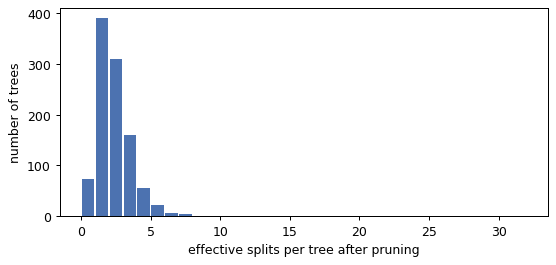

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(stats["effective_splits"], bins=range(0, stats["splits"].iloc[0] + 2), color="#4c72b0", rwidth=0.9)
ax.set_xlabel("effective splits per tree after pruning")
ax.set_ylabel("number of trees");

### 4.2 A single tree

`plot_tree` draws one tree of the ensemble by its index. Split nodes show the condition of the *yes* branch on
the original features (pass `feature_names`, otherwise the features are called `x_1, x_2, ...`). Leaves show
the class distribution of the leaf and, in a separate line,
the leaf weight (the logit of the instance-wise estimator weight). With `X=...` every node shows how many samples
reach it, and `highlight=...` marks the decision path of one sample.

We look at a test sequence of class `IE`, and plot the tree that receives the highest weight for it.

predicted probabilities: {'EI': 0.0, 'IE': 0.974, 'N': 0.026}, true class: IE, tree #709


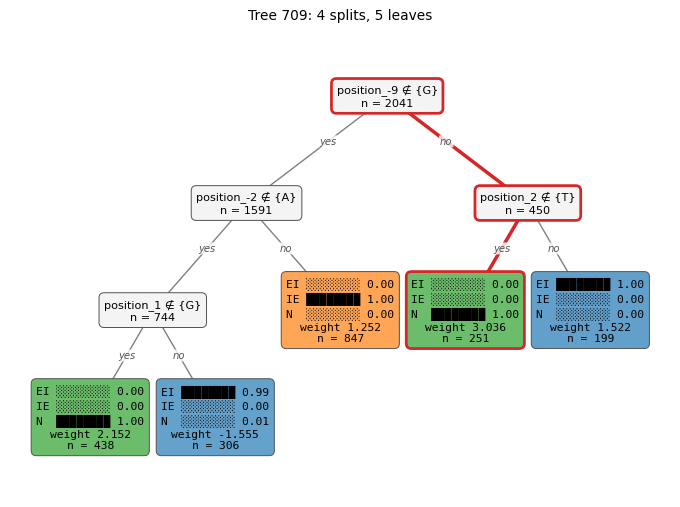

In [8]:
names = list(X.columns)
sample = X_test[y_test == "IE"].iloc[[0]]
explanation = model.explain_instance(sample)
tree_index = int(explanation["estimator"].iloc[0])  # the tree with the highest weight for this sample
proba = {c: round(float(p), 3) for c, p in zip(model.classes_, model.predict_proba(sample)[0])}
print(f"predicted probabilities: {proba}, true class: {y_test.loc[sample.index[0]]}, tree #{tree_index}")
model.plot_tree(tree_index, feature_names=names, X=X_train, highlight=sample);

The same tree as text. `export_text` is handy in a terminal or a log file:

In [9]:
print(model.export_text(tree_index, feature_names=names))

Tree 709: 4 splits (31 before pruning), 5 leaves, depth 3
position_-9 ∉ {G}
├─ yes: position_-2 ∉ {A}
│  ├─ yes: position_1 ∉ {G}
│  │  ├─ yes: leaf 12: P(EI)=0.000  P(IE)=0.000  P(N)=1.000  | weight=2.152
│  │  └─ no:  leaf 13: P(EI)=0.988  P(IE)=0.000  P(N)=0.012  | weight=-1.555
│  └─ no:  leaf 15: P(EI)=0.000  P(IE)=1.000  P(N)=0.000  | weight=1.252
└─ no:  position_2 ∉ {T}
   ├─ yes: leaf 17: P(EI)=0.000  P(IE)=0.000  P(N)=1.000  | weight=3.036
   └─ no:  leaf 19: P(EI)=1.000  P(IE)=0.000  P(N)=0.000  | weight=1.522


For comparison, the complete tree **before pruning** (`prune=False`). Redundant splits are dashed and annotated
with the branch they always take; branches that can never be reached are faded out.

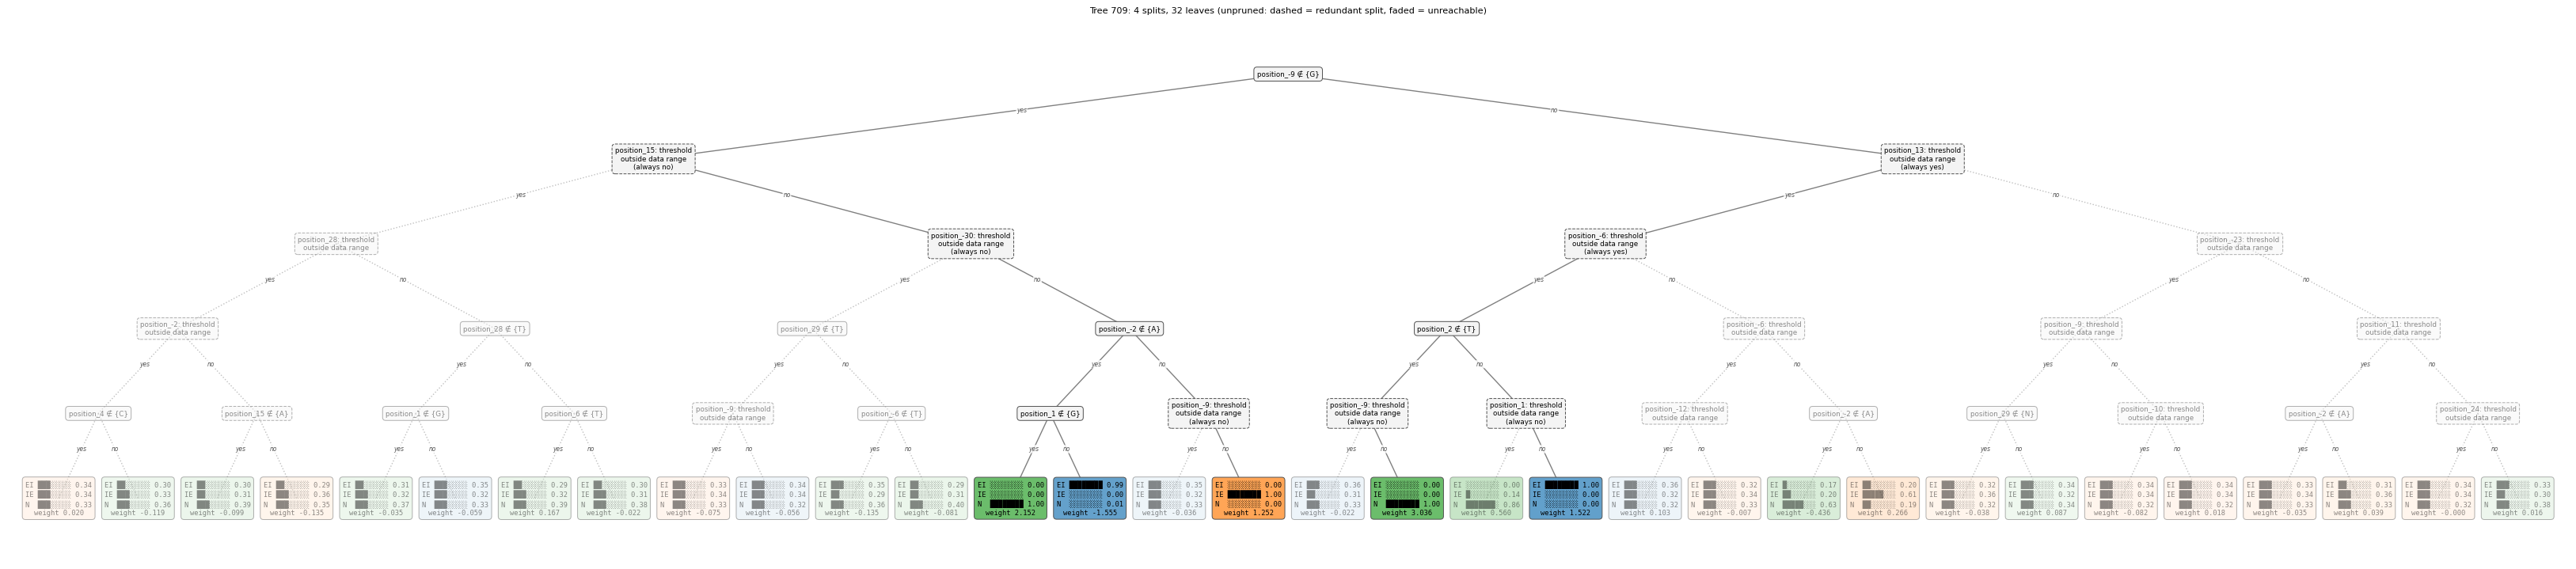

In [10]:
model.plot_tree(tree_index, prune=False, feature_names=names);

### 4.3 Feature importances

Two importance measures exploit the tree structure. Both only credit *effective* splits (see pruning) and
aggregate encodings and embedding dimensions to their original feature:

* **data-based** (`compute_feature_importances(X)`): for every sample and tree, the sample's estimator weight is
  shared among the effective splits on its decision path. A feature's importance is its share of all routing
  decisions of the ensemble on `X`.
* **structural** (`feature_importances_`, no data needed): every tree distributes its expected weight over its
  effective splits in proportion to the probability of reaching each split.

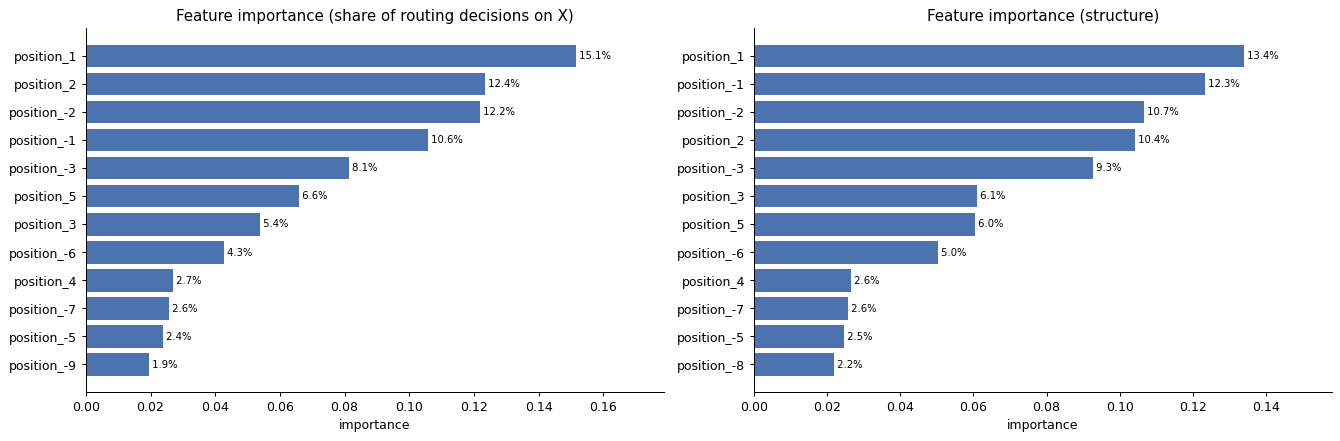

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
model.plot_feature_importances(X=X_test, feature_names=names, top_k=12, ax=axes[0])
model.plot_feature_importances(feature_names=names, top_k=12, ax=axes[1])
plt.tight_layout()

The positions directly around the splice junction (`position_-3` to `position_3`) dominate, in line with the
conserved dinucleotides (GT at the start and AG at the end of an intron) that mark splice sites.

### 4.4 Explaining a single prediction

For one sample, `explain_instance` lists every tree with the leaf it reaches, its instance-wise **weight**
(softmax over all trees, sums to 1) and its **contribution** to the prediction
(logit of the predicted class relative to the mean logit).

In [12]:
print({k: round(v, 4) if isinstance(v, float) else v for k, v in explanation.attrs.items()})
explanation.head(10).round(4)

{'effective_n_estimators': 224.4122, 'n_estimators': 1024, 'target': 'IE', 'score': 4.2264, 'prediction': 0.9741, 'prediction_label': 'P(IE)', 'contribution_unit': 'logit of IE vs. mean logit'}


,estimator,leaf,weight,weight_logit,leaf_prediction,contribution
0,709,17,0.0232,3.0364,0.0000,-0.1147
1,554,13,0.0158,2.6524,0.9997,0.1215
2,518,25,0.0153,2.6200,0.0000,-0.0378
3,168,18,0.0109,2.2803,0.9999,0.0806
4,669,19,0.0098,2.1729,0.0005,-0.0064
5,601,31,0.0097,2.1641,0.9999,0.0691
6,717,31,0.0095,2.1432,0.9999,0.0687
7,851,15,0.0093,2.1241,1.0000,0.0740
8,710,27,0.0092,2.1131,0.9998,0.0640
9,595,1,0.0083,2.0048,0.0010,-0.0004


`plot_estimator_weights` shows how the weight is distributed over the trees for this sample (the effective
number of trees is 1 / sum of squared weights), which trees receive the most weight and how much they
contribute:

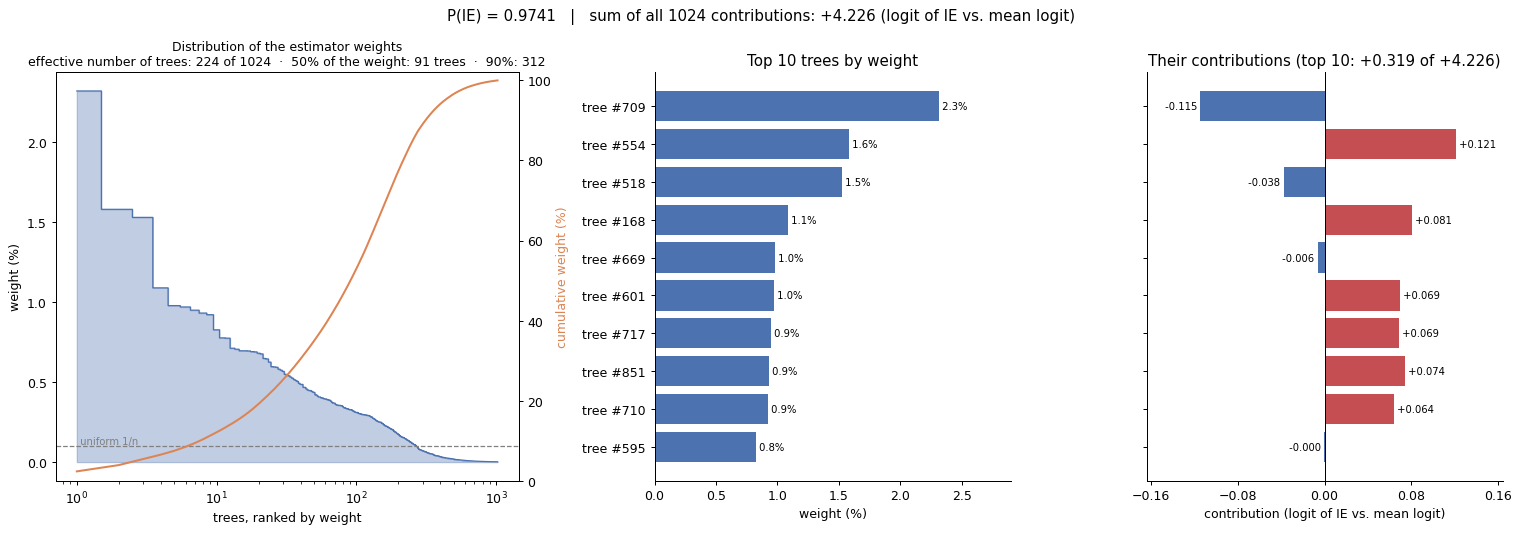

In [13]:
model.plot_estimator_weights(sample, top_k=10);

`plot_top_estimators` draws the trees with the highest weight for this sample side by side, with the decision
path of the sample highlighted:

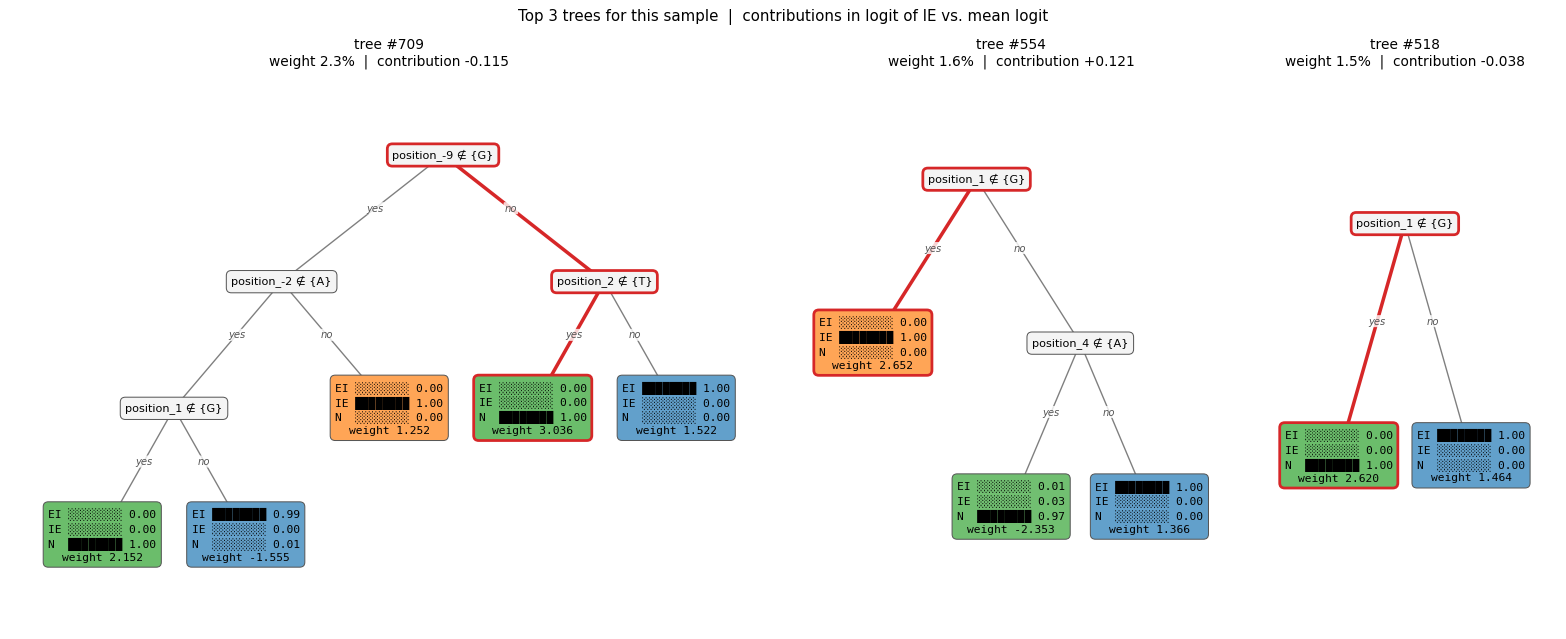

In [14]:
model.plot_top_estimators(sample, k=3, feature_names=names);

### 4.5 Which features drive this prediction?

The view above attributes the prediction to *trees*. `explain_features` attributes it to the *input features*
with Shapley values: each feature receives its average contribution over all orders in which features can be
switched from a reference sample to the explained sample. The references are a background sample of the
training data; the attributions add up to the prediction minus the mean prediction over the background
(in logits of the predicted class).

GRANDE weights its trees per sample, so the output is not a plain sum over trees and the usual TreeSHAP
shortcut does not apply. Instead, features that do not change any split for a background row are dropped
(they contribute exactly 0) and the remaining ones are enumerated exactly if there are at most 12 of them,
or sampled otherwise.

In [15]:
background = X_train.sample(100, random_state=0)
attributions = model.explain_features(sample, background, feature_names=names)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in attributions.attrs.items()})
attributions.head(8).round(4)

{'base_value': -0.9204, 'score': 4.2264, 'n_references': 100, 'n_exact': 0, 'n_sampled': 100, 'n_dummy_references': 0, 'unit': 'logit of IE vs. mean logit', 'prediction_label': 'P(IE)', 'prediction': 0.9741, 'target': 'IE'}


,feature,value,attribution
0,position_-2,A,1.4481
1,position_-1,G,1.0316
2,position_-3,C,0.6322
3,position_1,A,0.3759
4,position_-6,C,0.3274
5,position_3,T,0.2566
6,position_-11,T,0.2064
7,position_-5,T,0.1933


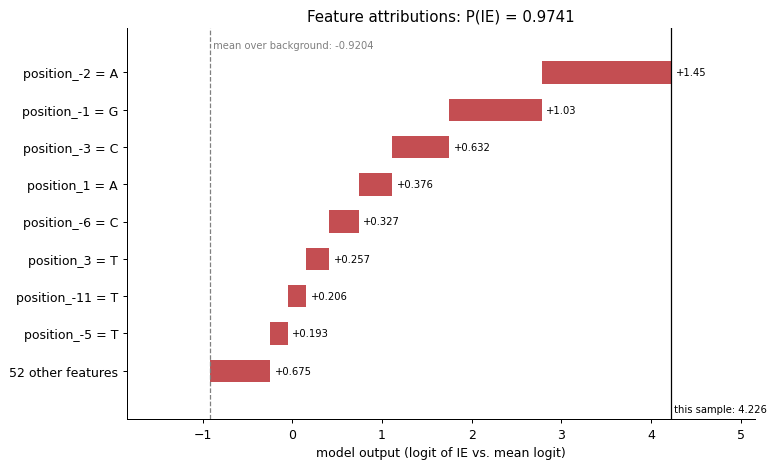

In [16]:
model.plot_feature_attributions(attributions=attributions, top_k=8);

### 4.6 Rules

Every leaf of a pruned tree is a readable rule: the conditions on its path. `extract_rules` ranks the leaves by
how much the ensemble relies on them (`weight_share`: the instance-wise estimator weight on the leaf, summed
over the covered samples) times how strongly they change the prediction (`lift`: increase of the predicted probability of the rule's class on the covered samples).
Broad rules that hold for nearly everybody therefore rank low. Leaves of different trees that cover almost
the same samples are merged (`n_trees`). The rules are extracted on the training data:

In [17]:
rules = model.extract_rules(X_train, y_train, top_k=10, feature_names=names)
print("mean prediction on the training data:", {k: round(v, 3) for k, v in rules.attrs['base'].items()})
rules.drop(columns=["tree", "leaf", "impact"]).round(3)

mean prediction on the training data: {'EI': 0.243, 'IE': 0.24, 'N': 0.516}


,rule,prediction,mean_probability,precision,lift,coverage,weight_share,n_trees
0,position_1 ≠ G,N,0.755,0.758,0.238,0.500,0.076,68
1,position_-1 ≠ G,N,0.896,0.901,0.380,0.424,0.042,38
2,position_-2 ≠ A,N,0.793,0.796,0.277,0.490,0.051,62
3,position_5 = G,EI,0.549,0.551,0.306,0.368,0.026,32
4,position_2 ≠ T,N,0.697,0.701,0.181,0.553,0.033,37
5,position_1 = G AND position_2 = T,EI,0.796,0.797,0.553,0.297,0.010,5
6,position_-2 ≠ A AND position_5 ≠ G,N,0.964,0.967,0.448,0.310,0.011,3
7,position_-1 ≠ G AND position_2 ≠ T,N,0.994,0.997,0.478,0.281,0.010,2
8,position_2 = T,EI,0.534,0.531,0.291,0.447,0.015,30
9,position_-3 = G,N,0.767,0.775,0.251,0.176,0.017,29


Do the rules hold on new data? We check the coverage and the precision of the same rules on the test data:

In [18]:
test_leaves = model.apply(X_test)
checks = []
for _, rule in rules.iterrows():
    covered = test_leaves[:, rule["tree"]] == rule["leaf"]
    checks.append({"rule": rule["rule"], "prediction": rule["prediction"], "test coverage": covered.mean(),
                   "test precision": (y_test.to_numpy()[covered] == rule["prediction"]).mean(),
                   "share of this class in the test data": (y_test == rule["prediction"]).mean()})
pd.DataFrame(checks).round(3)

,rule,prediction,test coverage,test precision,share of this class in the test data
0,position_1 ≠ G,N,0.497,0.716,0.519
1,position_-1 ≠ G,N,0.431,0.895,0.519
2,position_-2 ≠ A,N,0.498,0.811,0.519
3,position_5 = G,EI,0.392,0.532,0.240
4,position_2 ≠ T,N,0.531,0.696,0.519
5,position_1 = G AND position_2 = T,EI,0.321,0.746,0.240
6,position_-2 ≠ A AND position_5 ≠ G,N,0.303,0.990,0.519
7,position_-1 ≠ G AND position_2 ≠ T,N,0.263,0.994,0.519
8,position_2 = T,EI,0.469,0.512,0.240
9,position_-3 = G,N,0.196,0.736,0.519


## 5. Saving and loading

Fitted estimators can be pickled, or saved with `save` and loaded with `load`. `load(path, device="cpu")` moves
a model trained on a GPU to the CPU (predictions then differ slightly, as GPUs compute matrix products with
reduced precision, TF32).

In [19]:
import os

model.save("grande_splice.pt")
restored = GRANDEClassifier.load("grande_splice.pt")
print(f"restored on {restored.device_}, identical predictions: {np.array_equal(restored.predict_proba(X_test), model.predict_proba(X_test))}")
os.remove("grande_splice.pt")

restored on cuda:0, identical predictions: True
